# Week 3: Unsupervised Learning & Model Evaluation

Dataset: Breast Cancer Wisconsin dataset from Scikit-learn.

This notebook has two separate experiments:
1. Unsupervised learning with K-Means, Hierarchical Clustering, silhouette scores, the elbow method, and PCA.
2. Supervised classification with cross-validation, confusion matrix, precision, recall, F1-score, ROC-AUC, and hyperparameter tuning.



In [1]:
# Cell 1 — Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (silhouette_score, classification_report, accuracy_score,precision_score, recall_score, f1_score, roc_auc_score,ConfusionMatrixDisplay)
RANDOM_STATE = 42

In [2]:
# Cell 2 — Load and inspect the dataset
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target
print("Dataset shape:", X.shape)
print("Target classes:", dict(enumerate(data.target_names)))
print("Missing values:", X.isnull().sum().sum())
print("\nClass counts:")
print(y.map({0: "malignant", 1: "benign"}).value_counts())
display(X.head())
#rows and features-569 rows with 30 columns in each row
#Describe the numerical measurements in the dataset-The numerical measurements describe the characteristics of cell nuclei obtained from digitized images of breast mass samples. They include features such as radius, texture, perimeter, and area, which describe size and appearance. 
#0 = malignant and 1 = benign
#No missing values found

Dataset shape: (569, 30)
Target classes: {0: np.str_('malignant'), 1: np.str_('benign')}
Missing values: 0

Class counts:
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981,11.70,13.37,15.78,28.11
mean texture,569.0,19.289649,4.301036,9.710,16.17,18.84,21.80,39.28
mean area,569.0,654.889104,351.914129,143.500,420.30,551.10,782.70,2501.00


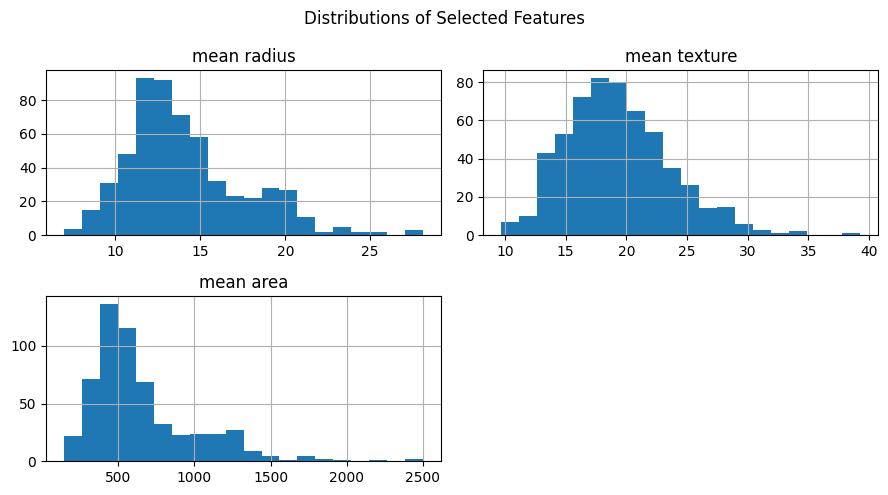

In [3]:
# Cell 3 — Explore selected feature distributions
selected_features = ["mean radius", "mean texture", "mean area"]
display(X[selected_features].describe().T)
X[selected_features].hist(figsize=(9, 5), bins=20)
plt.suptitle("Distributions of Selected Features")
plt.tight_layout()
plt.show()
#The mean area feature has a much larger numerical range and a more right-skewed distribution than mean radius and mean texture
#Unscaled large-range features can dominate distance calculations because K-Means and Hierarchical Clustering use distances to measure how similar two data points are.

,Potential outlier count
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
fractal dimension error,28
compactness error,28
symmetry error,27
mean area,25
worst fractal dimension,24


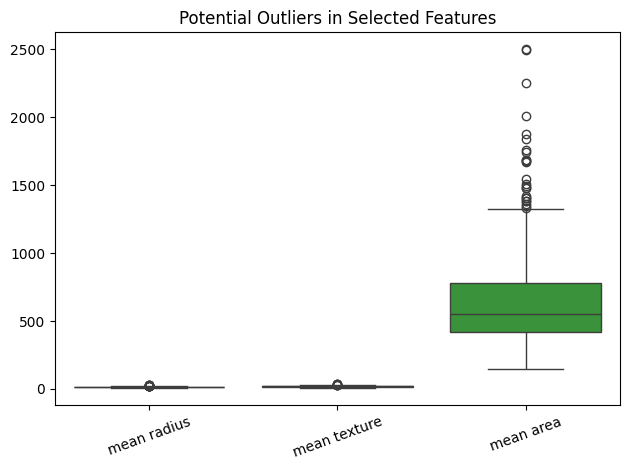

In [4]:
# Cell 4 — Inspect potential outliers using the IQR rule
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outlier_mask = (X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))
outlier_counts = outlier_mask.sum().sort_values(ascending=False)
display(outlier_counts.head(10).to_frame("Potential outlier count"))
sns.boxplot(data=X[selected_features])
plt.title("Potential Outliers in Selected Features")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

#features with many potential outliers-area error,radius error,perimeter error,worst area,smoothness error,fractal dimension error,compactness error,symmetry error,mean area,worst fractal dimension	
#These potential outliers may represent genuine variations in cell measurements rather than incorrect data. Deleting them could remove useful information and affect clustering or classification performance

In [5]:
# Cell 5 — Standardize features for clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)
print("Mean of first three scaled features:", np.round(X_scaled.mean(axis=0)[:3], 3))
print("Std. dev. of first three scaled features:", np.round(X_scaled.std(axis=0)[:3], 3))

#Standardization is important because features such as mean area have much larger numerical ranges than features such as mean radius.

Original shape: (569, 30)
Scaled shape: (569, 30)
Mean of first three scaled features: [-0. -0. -0.]
Std. dev. of first three scaled features: [1. 1. 1.]


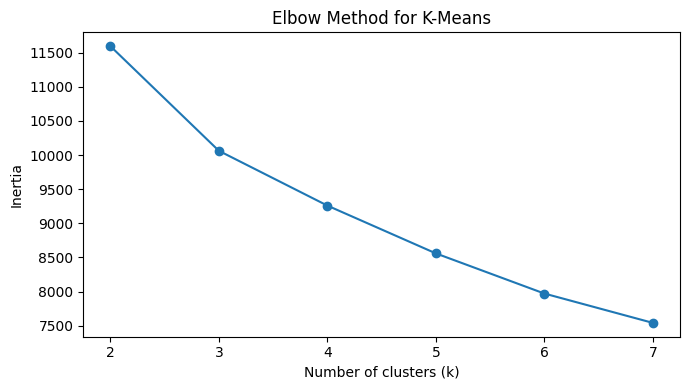

In [6]:
# Cell 6 — Elbow method for K-Means
k_values = range(2, 8)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

,Number of clusters,Silhouette score
0,2,0.343382
1,3,0.314384
2,4,0.283305
4,6,0.160367
3,5,0.158210
5,7,0.153186


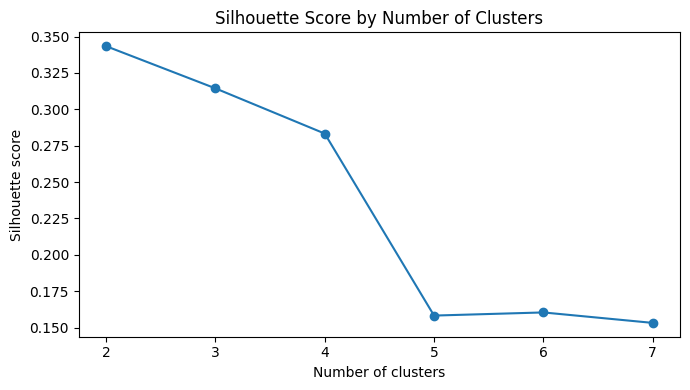

In [7]:
# Cell 7 — Compare silhouette scores for different cluster counts
silhouette_rows = []
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    silhouette_rows.append({
        "Number of clusters": k,
        "Silhouette score": silhouette_score(X_scaled, labels)
    })
silhouette_df = pd.DataFrame(silhouette_rows)
display(silhouette_df.sort_values("Silhouette score", ascending=False))
plt.figure(figsize=(7, 4))
plt.plot(silhouette_df["Number of clusters"], silhouette_df["Silhouette score"], marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score by Number of Clusters")
plt.xticks(list(range(2, 8)))
plt.tight_layout()
plt.show()

#K-Means with k=2 achieved the highest silhouette score (0.3434) among the tested cluster counts, so two clusters were selected for the comparison with Hierarchical Clustering.

In [8]:
# Cell 8 — Compare K-Means and Hierarchical Clustering with two clusters
kmeans = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
hierarchical = AgglomerativeClustering(n_clusters=2, linkage="ward")
hierarchical_labels = hierarchical.fit_predict(X_scaled)
cluster_comparison = pd.DataFrame({
    "Method": ["K-Means", "Hierarchical (Ward)"],
    "Silhouette score": [
        silhouette_score(X_scaled, kmeans_labels),
        silhouette_score(X_scaled, hierarchical_labels)]})
display(cluster_comparison.sort_values("Silhouette score", ascending=False))
print("K-Means cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())
print("\nHierarchical cluster sizes:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

,Method,Silhouette score
0,K-Means,0.343382
1,Hierarchical (Ward),0.339385


K-Means cluster sizes:
0    375
1    194
Name: count, dtype: int64

Hierarchical cluster sizes:
0    184
1    385
Name: count, dtype: int64


Variance explained by first two components: 0.6324


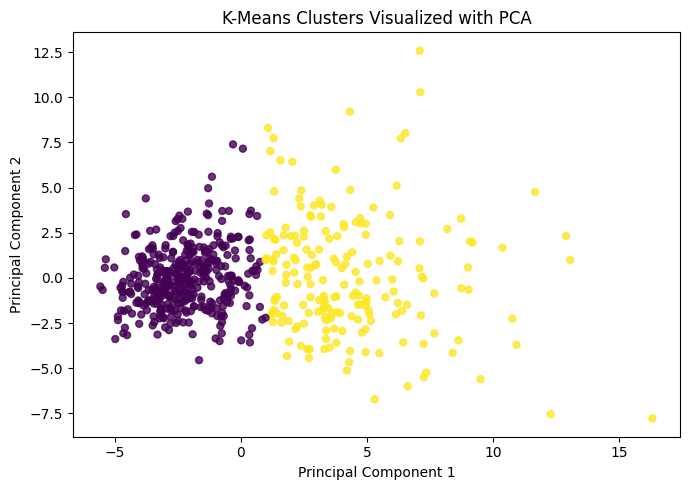

In [9]:
# Cell 9 — Visualize K-Means clusters using two PCA components
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)
print("Variance explained by first two components:",
      round(pca_2d.explained_variance_ratio_.sum(), 4))
plt.figure(figsize=(7, 5))
plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=kmeans_labels,cmap="viridis", s=25, alpha=0.8)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualized with PCA")
plt.tight_layout()
plt.show()
#The first two principal components explain 63.24% of the total variance.
#The clusters appear mostly separated, although some overlap is visible.
#This 2D plot is useful for visualization but cannot show all information contained in the original 30 features.

In [10]:
# Cell 10 — Test clustering after PCA retains 90% of variance

pca_90 = PCA(n_components=0.90)
X_pca_90 = pca_90.fit_transform(X_scaled)
kmeans_pca = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
labels_pca = kmeans_pca.fit_predict(X_pca_90)
pca_comparison = pd.DataFrame({
    "Representation": ["All 30 scaled features", "PCA features (90% variance)"],
    "Number of features": [X_scaled.shape[1], X_pca_90.shape[1]],
    "Variance retained": [1.0, pca_90.explained_variance_ratio_.sum()],
    "Silhouette score": [
        silhouette_score(X_scaled, kmeans_labels),
        silhouette_score(X_pca_90, labels_pca)]})
display(pca_comparison)


#PCA reduced the feature count from 30 to 7 while retaining approximately 91.01% of the variance. The silhouette score improved from 0.3434 to 0.3710, suggesting better cluster separation in this experiment.
#However,PCA may discard information, so this result should be interpreted alongside the variance retained and cluster structure.

,Representation,Number of features,Variance retained,Silhouette score
0,All 30 scaled features,30,1.000000,0.343382
1,PCA features (90% variance),7,0.910095,0.371034


In [11]:
# Cell 11 — Post-hoc interpretation of clusters using diagnosis labels

# Labels are used here only after clustering, not to fit the clustering model.
cluster_interpretation = pd.crosstab(
    pd.Series(kmeans_labels, name="K-Means cluster"),
    pd.Series(y.map({0: "malignant", 1: "benign"}), name="Known diagnosis"),normalize="index")
display(cluster_interpretation.round(3))


Known diagnosis,benign,malignant
K-Means cluster,,
0,0.904,0.096
1,0.093,0.907


## Part 2 — Supervised classification and model evaluation

This is a separate experiment. Diagnosis labels are used to train and evaluate classifiers. We use a stratified train/test split, fit scaling only on training data, and keep the test set out of hyperparameter selection.

In [12]:
# Cell 12 — Split labelled data into training and test sets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("\nTraining class proportions:")
print(y_train.map({0: "malignant", 1: "benign"}).value_counts(normalize=True).round(3))
print("\nTest class proportions:")
print(y_test.map({0: "malignant", 1: "benign"}).value_counts(normalize=True).round(3))

#Training and testing sizes-455(62%:37%),114(63%:36%)

Training samples: 455
Testing samples: 114

Training class proportions:
target
benign       0.626
malignant    0.374
Name: proportion, dtype: float64

Test class proportions:
target
benign       0.632
malignant    0.368
Name: proportion, dtype: float64


In [13]:
# Cell 13 — Train baseline Logistic Regression
# Pipeline ensures the scaler is fitted only on each training fold during CV.
lr_pipeline = make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)
y_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_lr, target_names=data.target_names, zero_division=0))

#malignant-p-0.98,r-0.98,f1-0.98
#benign-p-0.99,r-0.99,f1-0.99
#Class 0 is malignant and class 1 is benign.

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



,Model,Accuracy,Precision (benign positive),Recall (benign positive),F1 (benign positive),Malignant recall,ROC-AUC (benign positive)
0,Logistic Regression,0.982456,0.986111,0.986111,0.986111,0.97619,0.99537


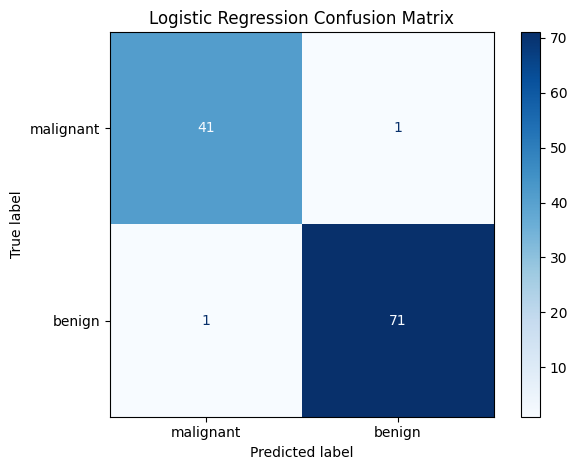

In [14]:
# Cell 14 — Calculate metrics and plot confusion matrix
def evaluate_classifier(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (benign positive)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall (benign positive)": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1 (benign positive)": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Malignant recall": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "ROC-AUC (benign positive)": roc_auc_score(y_true, y_prob)}
lr_metrics = evaluate_classifier("Logistic Regression", y_test, y_pred_lr, y_prob_lr)
display(pd.DataFrame([lr_metrics]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, display_labels=data.target_names, cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [15]:
# Cell 15 — Five-fold cross-validation for Logistic Regression

cv_f1_scores = cross_val_score(lr_pipeline, X_train, y_train, cv=5, scoring="f1")

print("F1 scores across folds:", np.round(cv_f1_scores, 4))
print("Mean cross-validation F1:", round(cv_f1_scores.mean(), 4))
print("Standard deviation:", round(cv_f1_scores.std(), 4))
#Mean F1-0.98, standard deviation-0.0101
# - Cross-validation is more informative than relying on one split alone.

F1 scores across folds: [0.9739 0.9821 0.9744 1.     0.9913]
Mean cross-validation F1: 0.9843
Standard deviation: 0.0101


In [16]:
# Cell 16 — Tune Random Forest using cross-validation on training data only

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 2]}

grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best mean cross-validation F1:", round(grid.best_score_, 4))

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Best mean cross-validation F1: 0.9684


,Model,Accuracy,Precision (benign positive),Recall (benign positive),F1 (benign positive),Malignant recall,ROC-AUC (benign positive)
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9762,0.9954
1,Tuned Random Forest,0.9561,0.9589,0.9722,0.9655,0.9286,0.9931


              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



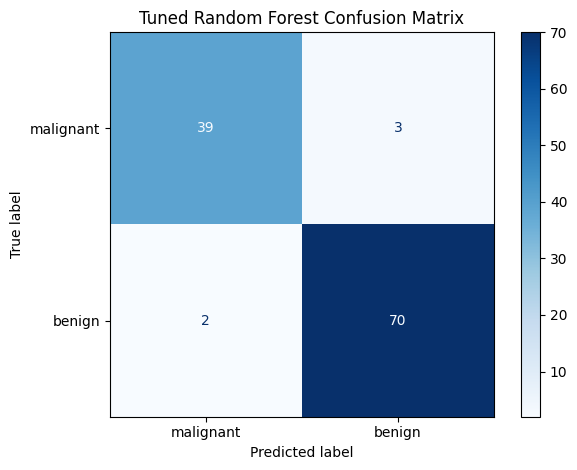

In [17]:
# Cell 17 — Evaluate tuned Random Forest on the held-out test set

best_rf = grid.best_estimator_
y_pred_rf = best_rf.predict(X_test)
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]

rf_metrics = evaluate_classifier("Tuned Random Forest", y_test, y_pred_rf, y_prob_rf)
model_comparison = pd.DataFrame([lr_metrics, rf_metrics])
display(model_comparison.round(4))

print(classification_report(y_test, y_pred_rf, target_names=data.target_names, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=data.target_names, cmap="Blues")
plt.title("Tuned Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

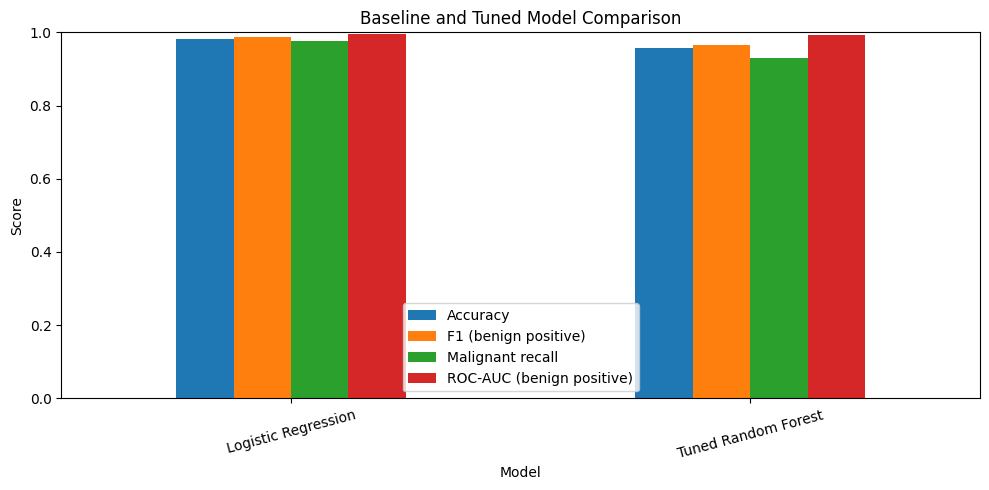

In [18]:
# Cell 18 — Visualize the model metric comparison
plot_metrics = model_comparison.set_index("Model")[["Accuracy", "F1 (benign positive)", "Malignant recall", "ROC-AUC (benign positive)"]]
plot_metrics.plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
plt.ylabel("Score")
plt.title("Baseline and Tuned Model Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#Logistic Regression achieved higher scores than the tuned Random Forest across all the metrics shown in the graph. It performed better in accuracy, F1-score, malignant recall, and ROC-AUC for this test set.
#The best model depends on the purpose of the task. Accuracy measures overall correctness, while F1-score balances precision and recall. Malignant recall is especially important in this example because low recall means more malignant cases may be incorrectly classified as benign. ROC-AUC measures how well the model distinguishes between the two classes across different classification thresholds.

In [19]:
# Cell 19 — Summary tables for your report

print("CLUSTERING SUMMARY")
display(cluster_comparison)
print("\nPCA COMPARISON")
display(pca_comparison)
print("\nCLASSIFICATION SUMMARY")
display(model_comparison.round(4))

#FINAL ANALYSIS
#1.K Means clustering method had the higher silhouette score
#2.The elbow plot showed how inertia decreased as the number of clusters increased. I used it to look for a point where the decrease began to slow down and considered this alongside the silhouette scores when selecting k.
#3.PCA changed the silhouette score compared with clustering on all 30 scaled features. I compared both scores to determine whether dimensionality reduction helped.
#4.I compared the proportion of malignant and benign samples in each K-Means cluster after clustering. This helped me understand how the clusters related to the known diagnosis labels.
#5.Logistic Regression performed better than tuned Random Forest in accuracy, F1-score, malignant recall, and ROC-AUC on the test set, as shown in thecomparison chart.
#6.Logistic Regression had higher malignant recall than tuned Random Forest in this experiment.
#7.Further improvement-I would test feature selection and compare hyperparameter tuning using macro F1-score or malignant recall, instead of optimizing only the default F1-score for the benign class. I would compare the results using cross-validation and the held-out test set.

CLUSTERING SUMMARY


,Method,Silhouette score
0,K-Means,0.343382
1,Hierarchical (Ward),0.339385



PCA COMPARISON


,Representation,Number of features,Variance retained,Silhouette score
0,All 30 scaled features,30,1.000000,0.343382
1,PCA features (90% variance),7,0.910095,0.371034



CLASSIFICATION SUMMARY


,Model,Accuracy,Precision (benign positive),Recall (benign positive),F1 (benign positive),Malignant recall,ROC-AUC (benign positive)
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9762,0.9954
1,Tuned Random Forest,0.9561,0.9589,0.9722,0.9655,0.9286,0.9931
